# **Test Ligand Class**

In [ ]:
from src.protein import Protein

# Esempio di utilizzo
pdb_path = ".\\data\\raw\\P-L\\2011-2019\\2l7u\\2l7u_protein.pdb"
pdb_poket_path = ".\\data\\raw\\P-L\\2011-2019\\2l7u\\2l7u_pocket.pdb"

protein_pdb = Protein.from_pdb_code("2l7u")
protein_path = Protein.from_pdb_path(pdb_path)
pocket = Protein.from_pdb_path(pdb_poket_path)

protein_pdb.visualize_protein_3D()
protein_path.visualize_protein_3D()
pocket.visualize_protein_3D()

Visualizzazione da codice PDB: 1a08


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Visualizzazione da file locale: .\data\raw\P-L\2011-2019\2l7u\2l7u_protein.pdb


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Visualizzazione da file locale: .\data\raw\P-L\2011-2019\2l7u\2l7u_pocket.pdb


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [2]:
print("proteina da PDB code:")
protein_pdb.visualize_protein_graph()
print("proteina da path:")
protein_path.visualize_protein_graph()
print("pocket:")
pocket.visualize_protein_graph()

proteina da PDB code:


Output()

proteina da path:


Output()

pocket:


Output()

In [8]:
protein= Protein.from_pdb_code("1a08")
protein.visualize_protein_graph()
x, edge_index, edge_attr, pos = protein.get_pyg_graph()

print(f"x: {x.shape}, edge_index: {edge_index.shape}, edge_attr: {edge_attr.shape}, pos: {pos.shape}")

print(edge_index)



Output()

x: torch.Size([211, 9]), edge_index: torch.Size([2, 2342]), edge_attr: torch.Size([2342, 2]), pos: torch.Size([211, 3])
tensor([[  0,   1,   0,  ..., 209, 210, 210],
        [  1,   0,   0,  ..., 209, 210, 210]])


In [9]:
print("Node features (x): [amminoacido embedding 7D + b_factor + res_name]")
print("[idrofobicità, volume sterico, Polarizzabilità, polarità, Potenziale Isuelettrico, Indice di Refrattività, Propensione per l'Elica alpha] [b_factor] [res_name]")
print (protein._get_node_features())

AMMINO_ACIDS_DICT = {
    'ALA': 0, 'ARG': 1, 'ASN': 2, 'ASP': 3, 'CYS': 4,
    'GLN': 5, 'GLU': 6, 'GLY': 7, 'HIS': 8, 'ILE': 9,
    'LEU': 10,'LYS': 11,'MET': 12,'PHE': 13,'PRO': 14,
    'SER': 15,'THR': 16,'TRP': 17,'TYR': 18,'VAL': 19
}

graph = protein.graph
for n, d in graph.nodes(data=True):
    meiler_vals = list(d['meiler']) 
    print(f"{n} - Meiler: ["
        f"h1:{meiler_vals[0]:.2f}, "
        f"h2:{meiler_vals[1]:.2f}, "
        f"h3:{meiler_vals[2]:.2f}, "
        f"h4:{meiler_vals[3]:.2f}, "
        f"h5:{meiler_vals[4]:.2f}, "
        f"h6:{meiler_vals[5]:.2f}, "
        f"h7:{meiler_vals[6]:.2f}] "
        f"- B-factor: {d['b_factor']:.2f}"
        f"- Residue Name: [{d['residue_name']}-{AMMINO_ACIDS_DICT.get(d['residue_name'], 99)}]")

Node features (x): [amminoacido embedding 7D + b_factor + res_name]
[idrofobicità, volume sterico, Polarizzabilità, polarità, Potenziale Isuelettrico, Indice di Refrattività, Propensione per l'Elica alpha] [b_factor] [res_name]
tensor([[ 1.3100,  0.0600,  1.6000,  ...,  0.2800, 45.3400, 15.0000],
        [ 4.1900,  0.1900,  4.0000,  ...,  0.4500, 27.1000,  9.0000],
        [ 1.5600,  0.1800,  3.9500,  ...,  0.2500, 17.2700,  5.0000],
        ...,
        [ 2.6700,  0.0000,  2.7200,  ...,  0.3400, 23.8600, 14.0000],
        [ 1.5600,  0.1500,  3.7800,  ...,  0.2100, 16.1900,  6.0000],
        [ 1.5600,  0.1500,  3.7800,  ...,  0.2100, 23.2700,  6.0000]])
A:SER:145 - Meiler: [h1:1.31, h2:0.06, h3:1.60, h4:-0.04, h5:5.70, h6:0.20, h7:0.28] - B-factor: 45.34- Residue Name: [SER-15]
A:ILE:146 - Meiler: [h1:4.19, h2:0.19, h3:4.00, h4:1.80, h5:6.04, h6:0.30, h7:0.45] - B-factor: 27.10- Residue Name: [ILE-9]
A:GLN:147 - Meiler: [h1:1.56, h2:0.18, h3:3.95, h4:-0.22, h5:5.65, h6:0.35, h7:0.25] -

In [10]:
print(edge_attr)

for u, v, d in graph.edges(data=True):
    print(d)
    print(f"Edge ({u}, {v}) - Type: {d['kind']} - Distance: {d['distance']:.2f} Å")

tensor([[1.0000, 3.7767],
        [1.0000, 3.7767],
        [0.0000, 0.0000],
        ...,
        [0.0000, 0.0000],
        [0.0000, 0.0000],
        [0.0000, 0.0000]])
{'kind': {'peptide_bond', 'distance_threshold'}, 'distance': np.float64(3.776654517410295)}
Edge (A:SER:145, A:ILE:146) - Type: {'peptide_bond', 'distance_threshold'} - Distance: 3.78 Å
{'kind': {'distance_threshold'}, 'distance': np.float64(0.0)}
Edge (A:SER:145, A:SER:145) - Type: {'distance_threshold'} - Distance: 0.00 Å
{'kind': {'distance_threshold'}, 'distance': np.float64(5.072283182064118)}
Edge (A:SER:145, A:GLN:147) - Type: {'distance_threshold'} - Distance: 5.07 Å
{'kind': {'distance_threshold'}, 'distance': np.float64(5.823856580092413)}
Edge (A:SER:145, A:ALA:148) - Type: {'distance_threshold'} - Distance: 5.82 Å
{'kind': {'distance_threshold'}, 'distance': np.float64(7.19872469908084)}
Edge (A:SER:145, A:GLU:149) - Type: {'distance_threshold'} - Distance: 7.20 Å
{'kind': {'peptide_bond', 'distance_thresho

tensor([[59.7270, 25.6890, 16.0580],
        [56.6080, 23.8290, 17.0950],
        [57.7020, 24.9350, 20.6470],
        [56.5900, 28.4460, 20.1170],
        [53.2160, 27.4830, 18.5500],
        [50.2790, 28.9050, 20.4780],
        [48.2390, 25.7130, 20.0690],
        [51.1450, 23.4550, 21.0820],
        [51.3270, 22.4760, 24.8030],
        [54.3840, 20.2520, 24.8000],
        [54.5640, 17.7020, 27.5610],
        [51.4570, 18.4760, 29.6820],
        [49.7250, 15.3580, 30.9740],
        [46.4520, 13.8780, 29.7480],
        [44.8590, 15.1410, 33.0090],
        [46.3690, 18.6460, 32.6040],
        [45.0240, 18.9750, 29.0740],
        [41.5260, 18.1270, 30.2380],
        [41.7780, 20.6600, 33.0940],
        [42.6460, 23.3010, 30.5970],
        [39.9550, 22.4710, 28.1400],
        [36.9950, 21.7940, 30.4980],
        [35.9300, 25.2870, 31.1320],
        [32.8650, 27.3640, 30.5350],
        [34.9010, 29.9530, 28.6410],
        [35.7690, 27.4830, 25.8290],
        [33.7730, 26.9560, 22.6030],
 

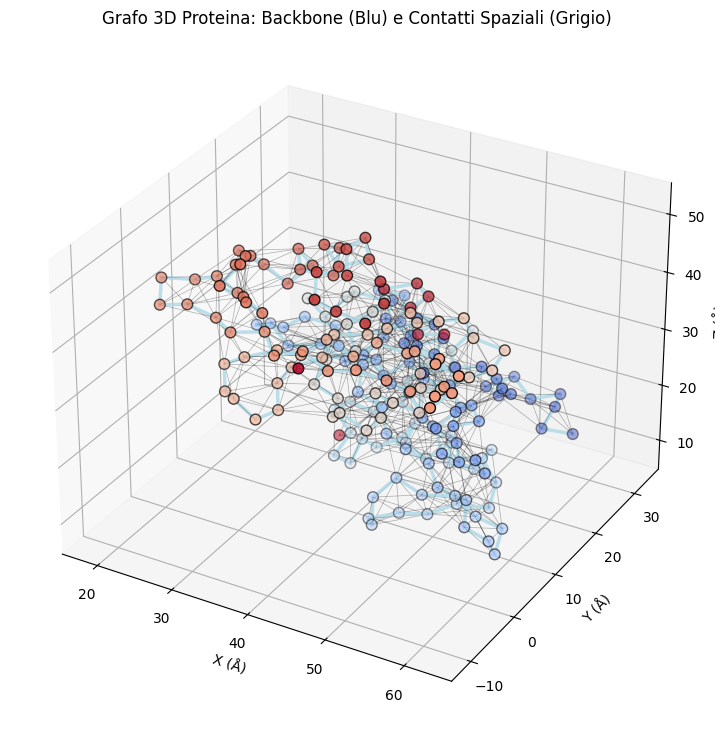

In [26]:
import matplotlib.pyplot as plt
import numpy as np

print(pos)
def plot_protein_graph_3d(pos, edge_index, edge_attr=None):
    """
    Visualizza il grafo della proteina in 3D usando Matplotlib.
    pos: tensore [N, 3] delle coordinate
    edge_index: tensore [2, E] degli indici dei legami
    edge_attr: opzionale, tensore [E, 2] dove la seconda colonna è il flag peptide_bond
    """
    fig = plt.figure(figsize=(12, 9))
    ax = fig.add_subplot(111, projection='3d')

    # 1. DISEGNO DEI NODI
    # Usiamo una sfumatura basata sulla posizione nella sequenza (indice del nodo)
    colors = np.linspace(0, 1, pos.shape[0])
    scatter = ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], 
                         c=colors, cmap='coolwarm', s=60, edgecolors='black', depthshade=True)

    # 2. DISEGNO DEGLI ARCHI (Edges)
    # Iteriamo su edge_index. Nota: edge_index è bidirezionale, 
    # ne prendiamo solo metà o usiamo un set per non disegnare due volte la stessa linea.
    seen_edges = set()
    
    # Trasponiamo per iterare sulle coppie [src, dst]
    edges = edge_index.t().numpy()
    
    for i, (src, dst) in enumerate(edges):
        # Ordiniamo la coppia per evitare duplicati (u,v) == (v,u)
        edge = tuple(sorted((src, dst)))
        if edge in seen_edges:
            continue
        seen_edges.add(edge)

        # Coordinate dei due punti
        p1 = pos[src]
        p2 = pos[dst]

        # Definiamo stile e colore in base al tipo di legame (se disponibile)
        color = 'black'
        linewidth = 0.5
        alpha = 0.3
        
        if edge_attr is not None:
            is_peptide = edge_attr[i, 0].item() # La colonna 1 è il flag peptide
            if is_peptide == 1.0:
                color = 'lightblue'  
                linewidth = 2.5
                alpha = 0.8
        
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], 
                color=color, linewidth=linewidth, alpha=alpha)

    # Impostazioni grafiche
    ax.set_title('Grafo 3D Proteina: Backbone (Blu) e Contatti Spaziali (Grigio)')
    ax.set_xlabel('X (Å)')
    ax.set_ylabel('Y (Å)')
    ax.set_zlabel('Z (Å)')
    
    # Per mantenere le proporzioni reali
    max_range = np.array([pos[:,0].max()-pos[:,0].min(), 
                          pos[:,1].max()-pos[:,1].min(), 
                          pos[:,2].max()-pos[:,2].min()]).max() / 2.0
    mid_x = (pos[:,0].max()+pos[:,0].min()) * 0.5
    mid_y = (pos[:,1].max()+pos[:,1].min()) * 0.5
    mid_z = (pos[:,2].max()+pos[:,2].min()) * 0.5
    ax.set_xlim(mid_x - max_range, mid_x + max_range)
    ax.set_ylim(mid_y - max_range, mid_y + max_range)
    ax.set_zlim(mid_z - max_range, mid_z + max_range)

    plt.show()

# Esecuzione:
plot_protein_graph_3d(pos, edge_index, edge_attr)